In [1]:
# Papermill parameters (edit here for an interactive run)
name = ""
fits_path = ""
fit_limit = 0.6
relative_uncertainty = 0.05
mcmc_steps = 50000
mcmc_burn = 1000
mcmc_thin = 50
mcmc_workers = 16

In [2]:
# Parameters
name = "stable_alpha1.5_moments_N64_L16_sigE1"
fits_path = "fits_ready/stable_alpha1.5_moments_N64_L16_sigE1.fits"
fit_limit = 0.9
relative_uncertainty = 0.05
mcmc_steps = 50000
mcmc_burn = 1000
mcmc_thin = 50
mcmc_workers = 16


# Ideal GSTools fits versus fitting fraction

Run from your project root, with `py_modules/bfunc.py` and
`py_modules/bplot_ideal.py` available. Input FITS must contain the `TABLE`
extension with `N pairs`, `Unweighted B(r)`, and `log10 r`, and primary
header keys `BOX_SIZE`, `PC`, and `PIX`.

For an interactive run, set `name` or `fits_path` in the parameters cell.
Papermill supplies them from `Makefile_fit_fractions_ideal`.

Only `r <= fit_limit * box_size` changes between fractions. The model is
`bfunc00s(r, r0, sig2, m)`, without seeing or noise parameters. Relative
uncertainty and parameter bounds remain fixed. `BOX_SIZE` is read directly
from the header (the map diagonal in your synthetic workflow).

The original notebook's first-point transformation is retained explicitly
for comparability. It discards the original second bin; it is not a true
one-point merge. Any future correction should be applied to every fraction.

Outputs use `_L020` ... `_L099`, including plots and the derived FITS.
The source FITS is never overwritten. Rerunning a fraction replaces its
previous derived file. `PARAMETERS` keeps the existing row convention:
LM value, upper offset, lower offset, using the 2.5–97.5 posterior percentiles.
These are 95% credible bounds; offsets can be negative if the LM optimum
lies outside that interval. MCMC diagnostics still require inspection.

Dependencies: your existing ideal-fit environment (including Papermill,
lmfit, emcee, Astropy, NumPy, pandas, matplotlib, seaborn, and corner).
Set `mcmc_workers = 1` if multiprocessing is unavailable.

In [3]:
import time
start_time = time.time()

In [4]:
import numpy as np
import seaborn as sns
import pandas as pd
import sys
from pathlib import Path
from matplotlib import pyplot as plt
from astropy.io import fits
from astropy.table import Table
import lmfit

sys.path.insert(0, str(Path.cwd() / "py_modules"))
import bfunc
import bplot_ideal

# Existing plotting helpers may save to these project folders.
for folder in ("Imgs", "results_fit"):
    Path(folder).mkdir(parents=True, exist_ok=True)

In [5]:
fit_limit = float(fit_limit)
relative_uncertainty = float(relative_uncertainty)
if not np.isfinite(fit_limit) or not 0 < fit_limit <= 1:
    raise ValueError("fit_limit must be in (0, 1].")
fit_percent = int(round(100 * fit_limit))
if fit_percent < 1 or not np.isclose(100 * fit_limit, fit_percent, rtol=0, atol=1e-8):
    raise ValueError("Use whole-percent fractions, e.g. 0.20 or 0.99.")
if not np.isfinite(relative_uncertainty) or relative_uncertainty <= 0:
    raise ValueError("relative_uncertainty must be finite and positive.")

if fits_path:
    input_fits_path = Path(fits_path).expanduser()
elif name:
    input_fits_path = Path("fits_ready") / f"{name}.fits"
else:
    raise ValueError("Set name or fits_path in the parameters cell.")
if input_fits_path.suffix.lower() != ".fits":
    raise ValueError("This workflow expects an uncompressed .fits input.")
if not input_fits_path.is_file():
    raise FileNotFoundError(input_fits_path)

fit_tag = f"L{fit_percent:03d}"
output_fits_path = input_fits_path.with_name(f"{input_fits_path.stem}_{fit_tag}.fits")
output_name = output_fits_path.stem
assert output_fits_path.resolve() != input_fits_path.resolve()

with fits.open(input_fits_path) as hdul:
    hdr = hdul[0].header.copy()
box_size = float(hdr["BOX_SIZE"])
pc = float(hdr["PC"])
pix = float(hdr["PIX"])
if not all(np.isfinite(x) and x > 0 for x in (box_size, pc, pix)):
    raise ValueError("BOX_SIZE, PC and PIX must be finite and positive.")
line = hdr.get("NAME_REG", hdr.get("LINE", input_fits_path.stem))

print(f"Input: {input_fits_path}")
print(f"Lfracc: {fit_limit:.2f}; output: {output_fits_path}")

Input: fits_ready\stable_alpha1.5_moments_N64_L16_sigE1.fits
Lfracc: 0.90; output: fits_ready\stable_alpha1.5_moments_N64_L16_sigE1_L090.fits


In [6]:
data = output_name
plot_label = f"{line} ({fit_tag})"

In [7]:
t = Table.read(input_fits_path, hdu="TABLE")
pairs = np.asarray(t["N pairs"], dtype=float)
B_all = np.asarray(t["Unweighted B(r)"], dtype=float)
r_all = 10.0 ** np.asarray(t["log10 r"], dtype=float) * pix * pc
mask = pairs > 0
B = B_all[mask].copy()
r = r_all[mask].copy()
if len(r) < 2:
    raise ValueError("Not enough SF bins with positive pair counts.")
if not np.all(np.isfinite(r) & (r > 0) & np.isfinite(B) & (B > 0)):
    raise ValueError("Populated SF bins must have finite, positive r and B(r).")
if not np.all(np.diff(r) > 0):
    raise ValueError("SF separations must be strictly increasing.")

# Fit and Confidence intervals

## Non-Linear Least-Squares Fitting

In [8]:
# Preserve the original ideal notebook's preprocessing across ALL fractions.
# With K=1, this retains the first bin and drops the original second bin.
K = 1
r[K] = np.mean(r[:K])
B[K] = np.mean(B[:K])
r = r[K:]
B = B[K:]

In [9]:
weights = 1.0 / (relative_uncertainty * B)
fit_cutoff = fit_limit * box_size
to_fit = r <= fit_cutoff
large_scale = ~to_fit
n_fit = int(np.sum(to_fit))
if n_fit <= 3:
    raise ValueError(f"{fit_tag}: need more than 3 SF bins; found {n_fit}.")
print(f"Cutoff = {fit_cutoff:g}; fitted bins = {n_fit}/{len(r)}")

Cutoff = 81.4587; fitted bins = 32/32


In [10]:
model = lmfit.Model(bfunc.bfunc00s)
model.param_names

['r0', 'sig2', 'm']

In [11]:
# Keep the original bounds independent of Lfracc.
# In particular, use the full processed B array, not B[to_fit].
B_max = float(B.max())
model.set_param_hint("r0", value=0.1 * box_size, min=0.01 * box_size, max=2 * box_size)
model.set_param_hint("sig2", value=0.5 * B_max, min=0.25 * B_max, max=2 * B_max)
model.set_param_hint("m", value=1.0, min=0.5, max=2.0)

In [12]:
pd.DataFrame(model.param_hints)

,r0,sig2,m
value,9.050967,0.481594,1.0
min,0.905097,0.240797,0.5
max,181.019336,1.926375,2.0


In [13]:
result = model.fit(B[to_fit], weights=weights[to_fit], r=r[to_fit])
if not result.success:
    raise RuntimeError(f"Least-squares fit failed: {result.message}")

In [14]:
result

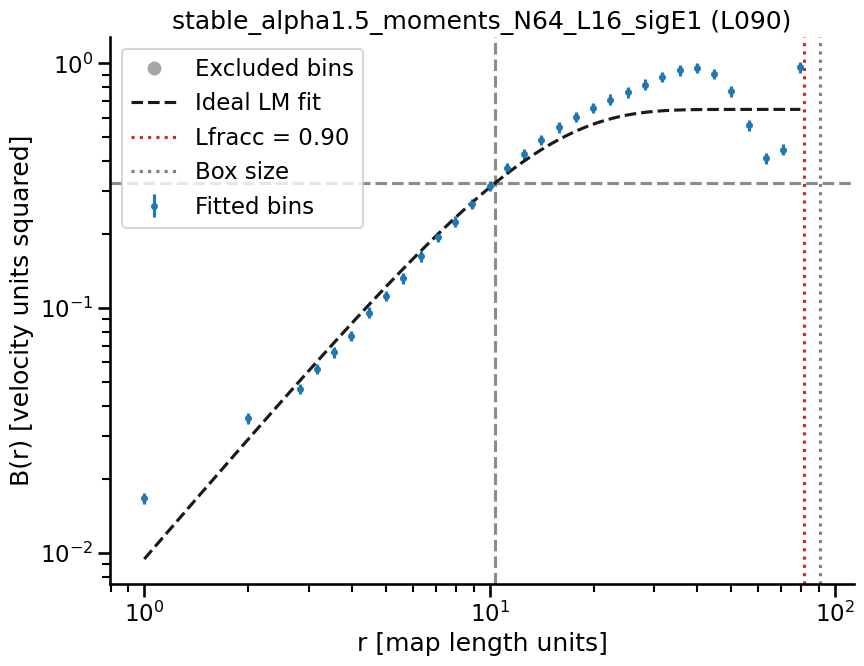

In [15]:
def plot_fraction_fit(posterior=False):
    fig, ax = plt.subplots(figsize=(9, 7))
    ax.errorbar(r[to_fit], B[to_fit], yerr=1 / weights[to_fit],
                fmt="o", ms=4, label="Fitted bins")
    ax.plot(r[large_scale], B[large_scale], "o", color="0.65", label="Excluded bins")
    rr = np.geomspace(r.min(), r.max(), 300)
    yy = result.eval(r=rr)
    ax.plot(rr, yy, "k--", label="Ideal LM fit")
    if posterior:
        chain = result_emcee.flatchain
        rng = np.random.default_rng(42)
        indices = rng.choice(len(chain), min(300, len(chain)), replace=False)
        curves = np.array([
            bfunc.bfunc00s(rr, row.r0, row.sig2, row.m)
            for row in chain.iloc[indices].itertuples()
        ])
        lo, hi = np.percentile(curves, [2.5, 97.5], axis=0)
        ax.fill_between(rr, lo, hi, color="C0", alpha=0.2, label="95% model band")
    ax.axvline(fit_cutoff, color="C3", ls=":", label=f"Lfracc = {fit_limit:.2f}")
    ax.axvline(box_size, color="0.5", ls=":", label="Box size")
    ax.axvline(result.params["r0"].value, color="k", ls="--", alpha=0.5)
    ax.axhline(result.params["sig2"].value, color="k", ls="--", alpha=0.5)
    if fit_cutoff < r.max():
        ax.axvspan(fit_cutoff, r.max(), color="k", alpha=0.05, zorder=-1)
    ax.set(xscale="log", yscale="log", xlabel="r [map length units]",
           ylabel="B(r) [velocity units squared]", title=plot_label)
    ax.legend()
    sns.despine()
    fig.tight_layout()
    suffix = "posterior" if posterior else "LM"
    fig.savefig(Path("Imgs") / f"{output_name}_{suffix}.pdf", bbox_inches="tight")
    return fig, ax

fig, ax = plot_fraction_fit()

## emcee

In [16]:
if not (int(mcmc_steps) > int(mcmc_burn) >= 0 and int(mcmc_thin) >= 1
        and int(mcmc_workers) >= 1):
    raise ValueError("Invalid MCMC steps, burn, thin or workers.")
emcee_kws = dict(
    steps=int(mcmc_steps), burn=int(mcmc_burn), thin=int(mcmc_thin),
    is_weighted=True, progress=False, workers=int(mcmc_workers),
)
emcee_params = result.params.copy()

In [17]:
result_emcee = model.fit(
    data=B[to_fit],
    r=r[to_fit],
    weights=weights[to_fit],
    params=emcee_params,
    method="emcee",
    nan_policy="omit",
    fit_kws=emcee_kws,
)

In [18]:
result_emcee

Text(0, 0.5, 'acceptance fraction')

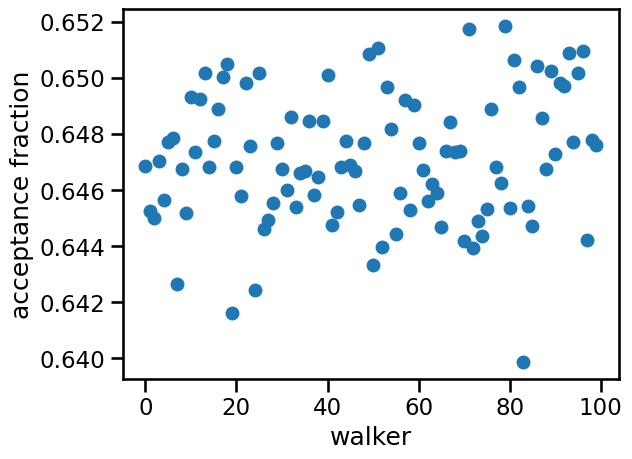

In [19]:
plt.plot(result_emcee.acceptance_fraction, "o")
plt.xlabel("walker")
plt.ylabel("acceptance fraction")



In [20]:
if hasattr(result_emcee, "acor"):
    print("Autocorrelation time for the parameters:")
    print("----------------------------------------")
    for i, p in enumerate(result_emcee.params):
        try:
            print(f"{p} = {result_emcee.acor[i]:.3f}")
        except IndexError:
            pass

Autocorrelation time for the parameters:
----------------------------------------
r0 = 38.417
sig2 = 38.436
m = 38.526


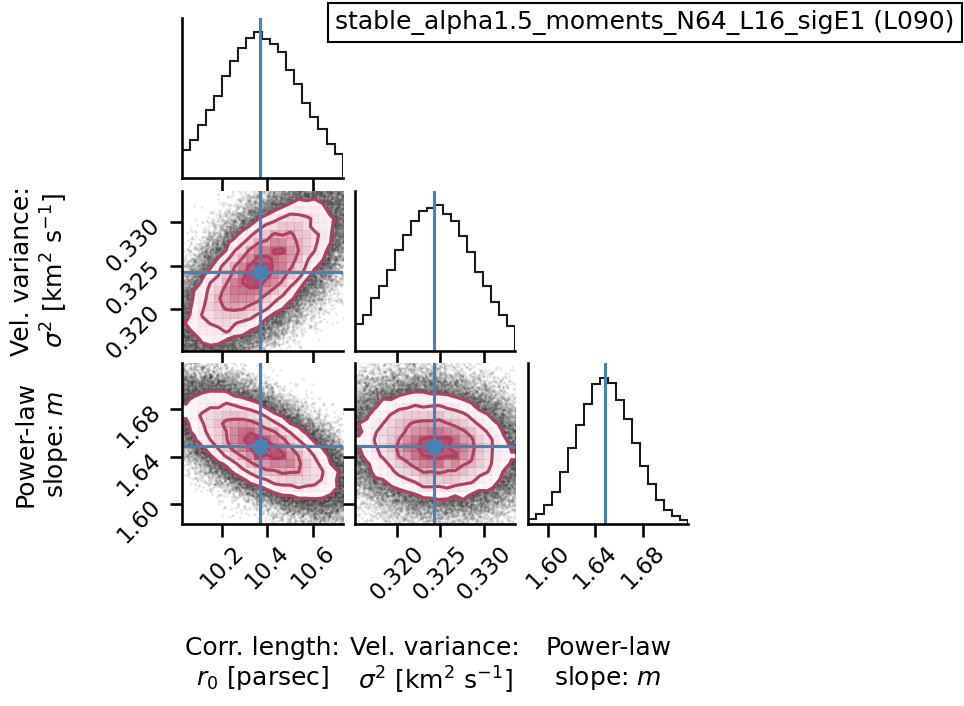

In [21]:
bplot_ideal.corner_plot(
    result_emcee, result, plot_label, data, data_ranges=[0.95, 0.95, 0.995]
)

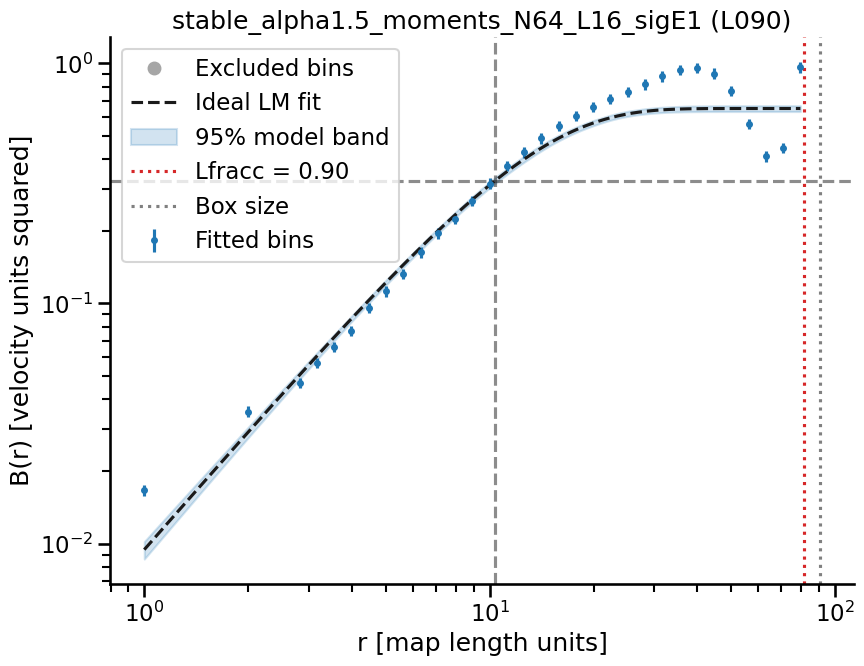

In [22]:
# Local plot uses the actual fraction cutoff, with no fixed box_size/2 shading.
fig, ax = plot_fraction_fit(posterior=True)

In [23]:
LM = {
    'sig2': [result.params['sig2'].value,result.params['sig2'].stderr],
    'r0': [result.params['r0'].value,result.params['r0'].stderr],
    'm' : [result.params['m'].value,result.params['m'].stderr],
}

In [24]:
MCMC = {
    'sig2': [result_emcee.params['sig2'].value,result_emcee.params['sig2'].stderr],
    'r0': [result_emcee.params['r0'].value,result_emcee.params['r0'].stderr],
    'm' : [result_emcee.params['m'].value,result_emcee.params['m'].stderr],
}

In [25]:
sig2s2 = np.percentile(result_emcee.flatchain['sig2'],[2.5, 97.5])
r0s2 = np.percentile(result_emcee.flatchain['r0'],[2.5, 97.5])
ms2 = np.percentile(result_emcee.flatchain['m'],[2.5, 97.5])

In [26]:
sig2s2p = sig2s2[1]-result.params['sig2'].value
sig2s2m = result.params['sig2'].value-sig2s2[0]

r0s2p = r0s2[1]-result.params['r0'].value
r0s2m = result.params['r0'].value-r0s2[0]

ms2p = ms2[1]-result.params['m'].value
ms2m = result.params['m'].value-ms2[0]

In [27]:
sig2s1 = np.percentile(result_emcee.flatchain['sig2'],[16, 84])
r0s1 = np.percentile(result_emcee.flatchain['r0'],[16, 84])
ms1 = np.percentile(result_emcee.flatchain['m'],[16, 84])

sig2s1p = sig2s1[1]-result.params['sig2'].value
sig2s1m = result.params['sig2'].value-sig2s1[0]

r0s1p = r0s1[1]-result.params['r0'].value
r0s1m = result.params['r0'].value-r0s1[0]

ms1p = ms1[1]-result.params['m'].value
ms1m = result.params['m'].value-ms1[0]

In [28]:
results_2sig = {
    'sig2': [result.params['sig2'].value,sig2s2p,sig2s2m],
    'r0': [result.params['r0'].value,r0s2p,r0s2m],
    'm' : [result.params['m'].value,ms2p,ms2m],
    
}

results_2sig

{'sig2': [0.3243100676118727, 0.009307928044041236, 0.009112928339291004],
 'r0': [10.367841023101063, 0.36046289946462373, 0.33964257964060884],
 'm': [1.6487752656212096, 0.04808998701919154, 0.046417429277522126]}

In [29]:
# PARAMETERS stores 95% posterior percentile bounds as offsets from the LM value.
# It intentionally retains the original column and row layout.
pd.DataFrame(results_2sig, index=["LM value", "upper offset", "lower offset"])

,sig2,r0,m
LM value,0.324310,10.367841,1.648775
upper offset,0.009308,0.360463,0.048090
lower offset,0.009113,0.339643,0.046417


In [30]:
new_hdu = fits.BinTableHDU(Table.from_pandas(pd.DataFrame(results_2sig)), name="PARAMETERS")
new_hdu.header["ROW0"] = "LM value"
new_hdu.header["ROW1"] = "97.5 percentile minus LM"
new_hdu.header["ROW2"] = "LM minus 2.5 percentile"
new_hdu.header["CILEVEL"] = (0.95, "Central posterior interval probability")

with fits.open(input_fits_path, memmap=False) as hdul:
    hdus = [h.copy() for h in hdul]
indices = [i for i, h in enumerate(hdus) if h.name.upper() == "PARAMETERS"]
if indices:
    hdus[indices[0]] = new_hdu
    for i in reversed(indices[1:]):
        del hdus[i]
else:
    hdus.append(new_hdu)
# Do not copy the old table header: its column layout may have five parameters.
primary = hdus[0].header
primary["FITFRAC"] = (fit_limit, "Maximum fitted separation / box size")
primary["FITMODEL"] = ("bfunc00s", "Structure function model")
primary["RELUNC"] = (relative_uncertainty, "Fixed fractional uncertainty")
primary["NFIT"] = (n_fit, "Number of SF bins fitted")
primary["FITRMAX"] = (fit_cutoff, "Requested fitting cutoff in map length units")
primary["REDCHI"] = (float(result.redchi), "LM reduced chi squared")
primary["NAME_ID"] = (output_name, "Pipeline identifier")
primary["FILE"] = (output_fits_path.name, "FITS file name")
primary.add_history(f"Ideal fraction fit from {input_fits_path.name}")
primary.add_history("Original K=1 first-point preprocessing retained.")

# Write atomically so failed runs cannot leave a partial Make target.
temporary_path = output_fits_path.with_suffix(".fits.tmp")
try:
    with fits.HDUList(hdus) as output_hdul:
        output_hdul.writeto(temporary_path, overwrite=True, checksum=True)
    temporary_path.replace(output_fits_path)
finally:
    if temporary_path.exists():
        temporary_path.unlink()
print(f"Saved: {output_fits_path}")

Saved: fits_ready\stable_alpha1.5_moments_N64_L16_sigE1_L090.fits


In [31]:
df_loaded = Table.read(output_fits_path, hdu="PARAMETERS").to_pandas()
df_loaded

,sig2,r0,m
0,0.324310,10.367841,1.648775
1,0.009308,0.360463,0.048090
2,0.009113,0.339643,0.046417


In [32]:
with fits.open(output_fits_path) as hdul:
    hdul.info()
    print("FITFRAC =", hdul[0].header["FITFRAC"])
    print("FITMODEL =", hdul[0].header["FITMODEL"])

Filename: fits_ready\stable_alpha1.5_moments_N64_L16_sigE1_L090.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      57   ()      
  1  MOM0          1 ImageHDU        37   (64, 64)   float64   
  2  MOM1          1 ImageHDU        35   (64, 64)   float64   
  3  TABLE         1 BinTableHDU     25   39R x 7C   [D, D, D, D, K, D, D]   
  4  PARAMETERS    1 BinTableHDU     21   3R x 3C   [D, D, D]   


FITFRAC = 0.9
FITMODEL = bfunc00s


In [33]:
print("--- %s seconds ---" % (time.time() - start_time))

--- 233.93661880493164 seconds ---
